# Module 7 Lab 1: Train, Test, Tell the Truth

## Step 1: Load tips.csv and frame the problem
#### Load the file. Your feature is total_bill, your target is tip. Build X and y and split 70/30 with random_state=42

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("tips.csv")

X = df[["total_bill"]]
y=df[["tip"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print("\nThe four objects created:")
print("1. X_train shape:", X_train.shape)
print("2. X_test shape:", X_test.shape)
print("3. y_train shape:", y_train.shape)
print("4. y_test shape:", y_test.shape)


The four objects created:
1. X_train shape: (170, 1)
2. X_test shape: (74, 1)
3. y_train shape: (170, 1)
4. y_test shape: (74, 1)


## Step 2: Why hold out 30%? (markdown cell)

#### In 2–3 sentences, explain why we grade on data the model never saw.

We hold out 30% of the data to test how well our model can generalize to new, unseen examples rather than just memorizing the data it was trained on. If we used the same data to test it, the model could just repeat memorized answers. Evaluating on held out data allows us to give an honest assement on how the model will preform in the real world.

## Step 3: Fit the regression and read the slope
#### Fit a LinearRegression (Tutorial 2) and print its slope and intercept (Tutorial 3). Write the slope sentence in markdown: each extra dollar of bill adds about ___ of tip.

In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))

print("The slope is:",model.coef_)
print("The intercept is:", model.intercept_)

0.4291782688312412
The slope is: [[0.10889371]]
The intercept is: [0.87695764]


Each extra dollar results in abot $0.11 more in tip.

## Step 4: Draw the fitted line

Scatter total_bill vs. tip and overlay the fitted line, fully labeled.

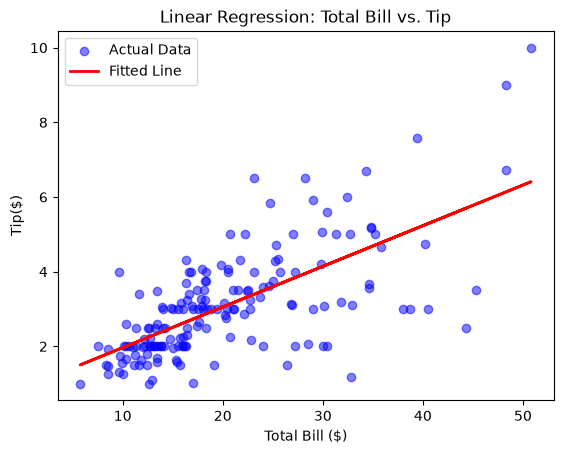

In [13]:
import matplotlib.pyplot as plt
plt.scatter(X_train, y_train, color="blue", alpha=0.5, label="Actual Data")
plt.plot(X_train, model.predict(X_train), color="red", linewidth=2, label="Fitted Line")

plt.title("Linear Regression: Total Bill vs. Tip")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip($)")
plt.legend()

## Step 5: Load iris and split it
#### Load iris with from sklearn.datasets import load_iris (call it with as_frame=True for readable columns), build X and y, and split 70/30 with the same random_state.

In [15]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

X= iris.data
y=iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state = 42
)

print("Total flowers:", len(X))
print("Flowers in training:", len(X_train))

Total flowers: 150
Flowers in training: 105


## Step 6: Fit and score kNN
#### Fit a 5-neighbor kNN (Tutorial 4) and score it on the TEST set only.

In [16]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

test_score = knn.score(X_test, y_test)

print("Test set score:", test_score)

Test set score: 1.0


## Step 7: Fit, score, and read a shallow tree
#### Fit a DecisionTreeClassifier with max_depth=3, score on test, and draw it (Tutorial 5). In markdown, translate the root split into a plain sentence.

Test set score: 1.0


[Text(0.375, 0.875, 'petal length (cm) <= 2.45\ngini = 0.664\nsamples = 105\nvalue = [31, 37, 37]\nclass = versicolor'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 31\nvalue = [31, 0, 0]\nclass = setosa'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'petal length (cm) <= 4.75\ngini = 0.5\nsamples = 74\nvalue = [0, 37, 37]\nclass = versicolor'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'petal width (cm) <= 1.6\ngini = 0.059\nsamples = 33\nvalue = [0, 32, 1]\nclass = versicolor'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 32\nvalue = [0, 32, 0]\nclass = versicolor'),
 Text(0.375, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.75, 0.375, 'petal width (cm) <= 1.75\ngini = 0.214\nsamples = 41\nvalue = [0, 5, 36]\nclass = virginica'),
 Text(0.625, 0.125, 'gini = 0.5\nsamples = 8\nvalue = [0, 4, 4]\nclass = versicolor'),
 Text(0.875, 0.125, 'gini = 0.059\nsamples = 33\nvalue = [0, 1, 32]\nclass = virginica')]

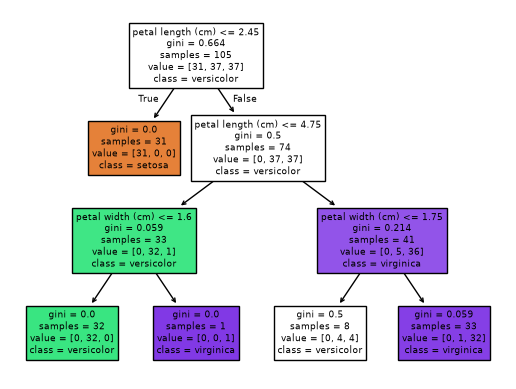

In [22]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)

dt_test_score = dt.score(X_test, y_test)
print("Test set score:", dt_test_score)

plot_tree(dt, feature_names=X.columns, class_names=iris.target_names, filled=True)

The first happens depending on whether the petal width is less than or equal to 2.45 cm. If it is less than or equal to 2.45cm it is split off into setosa class, and if it is not it is into versicolor class where it is split a few more times.

## Step 8: The overfitting probe
#### Refit the tree with NO max_depth. Using Tutorial 6, print train and test scores for BOTH trees in a small table (markdown or printed). One sentence: what do you observe?

In [24]:
dt_deep = DecisionTreeClassifier(max_depth=None, random_state=42)
dt_deep.fit(X_train, y_train)

train_score_shallow = dt.score(X_train, y_train)
test_score_shallow = dt.score(X_test, y_test)

train_score_deep = dt_deep.score(X_train, y_train)
test_score_deep = dt_deep.score(X_test, y_test)

print(f"{'Model':<20} | {'Train Score':<12} | {'Test Score'}")
print("-" * 50)
print(f"{'Shallow Tree (d=3)':<20} | {train_score_shallow:<12.4f} | {test_score_shallow:.4f}")
print(f"{'Deep Tree (No max)':<20} | {train_score_deep:<12.4f} | {test_score_deep:.4f}")

Model                | Train Score  | Test Score
--------------------------------------------------
Shallow Tree (d=3)   | 0.9524       | 1.0000
Deep Tree (No max)   | 1.0000       | 1.0000


I noticed that the deep tree did better on train but scored the same on test, showing that thee simpler model was just as good at predicting as the the complex one.

## Step 9: Predict one new flower
#### Invent one plausible flower measurement and predict its species with your preferred model.

In [25]:
X.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [27]:
new_flower=pd.DataFrame([[6.1, 3.1, 4.4, 1.7]], columns=X.columns)

prediction_number = dt.predict(new_flower)

predicted_species = iris.target_names[prediction_number[0]]

print("The model predicts this flower is a:", predicted_species)

The model predicts this flower is a: virginica


## Step 10: The model report (markdown cell)
#### About 6 sentences: what was predicted, which model you would ship and its test score, one scenario where it might fail, and one bias risk if this were a model about people instead of flowers.

We built a machine learning model to predict a specific species of an Iris flower based on sepal length, sepal width, petal length, and petal width. I would choose the shallow decision tree, max depth of 3, because it got a perfect test score while avoiding overfitting. This model could fail in the real world if it comes across a different species of iris flower it was not trained on, or if different units of measurments are used. If this type of model ws used for people as opposed to flowers, it has a risk of using human bias and discrimination found within historical data. Depending on what the machine learning model was being used for, it can negatively affect outcomes for people who were historically racially profiled.

#### Github URL
https://github.com/Alexisyarbs/cs82a-portfolio/blob/main/module%207/module7_lab1.ipynb